# Notebook 02 — Time-Leakage Ispati

**Amac:** Chicco & Jurman (2020) calismasinda kullanilan `time` ozelliginin
*temporal leakage* icerdigini uc bagimsiz deneyle kanitlamak.

> *"We extend Chicco & Jurman (2020) by demonstrating that the follow-up*
> *duration variable introduces temporal leakage, inflating reported MCC*
> *scores beyond what is achievable in clinical practice."*

## Deney Plani

| Deney | Baslik | Kanitlenen Sey |
|-------|--------|----------------|
| **A** | Target Leakage Testi | `time` korrelatif: outcome'in sebebi degil sonucu |
| **B** | Future Information Ispati | Model gruba gore 'hep olur' / 'hep yasar' der |
| **C** | Kabul Ani Ozellikleri | `time` cikinca MCC gercek klinik performansa duser |

**On kosul:** NB01 tamamlanmis olmali (NB01_scenario_comparison.csv gerekli).


In [23]:
# -- Hucre 1: Imports & Ortam Kurulumu --------------------------------------
import sys, os, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit
from sklearn.metrics import matthews_corrcoef, f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# -- Google Drive baglantisi (Colab) -----------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# -- utils.py yolu ------------------------------------------------------------
BASE = '/content/drive/MyDrive/HF_Revisit_Project' if IN_COLAB else '.'
if BASE not in sys.path:
    sys.path.insert(0, BASE)

from utils import (
    set_seed, load_and_verify_data, get_logger,
    save_figure, save_csv, save_run_log, set_plot_style,
    TARGET, CONTINUOUS_FEATURES, BINARY_FEATURES,
    COLOR_ALIVE, COLOR_DEAD
)

set_seed(42)
set_plot_style()
logger = get_logger('NB02')

RESULTS_DIR = os.path.join(BASE, 'results')
FIGURES_DIR = os.path.join(RESULTS_DIR, 'figures')

logger.info('NB02 baslatildi - Time-Leakage Ispati')
print('OK Ortam hazir.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[utils] Random seed sabitlendi → 42
09:56:07 | NB02 | INFO | NB02 baslatildi - Time-Leakage Ispati


INFO:NB02:NB02 baslatildi - Time-Leakage Ispati


OK Ortam hazir.


In [24]:
# -- Hucre 2: Veri Yukleme --------------------------------------------------
df = load_and_verify_data(os.path.join(BASE, 'data',
    'heart_failure_clinical_records_dataset.csv'))

# NB01 senaryo karsilastirma tablosunu yukle
scenario_path = os.path.join(RESULTS_DIR, 'NB01_scenario_comparison.csv')
if os.path.exists(scenario_path):
    df_scenario = pd.read_csv(scenario_path)
    logger.info('NB01_scenario_comparison.csv yuklendi')
    NB01_AVAILABLE = True
else:
    logger.warning('NB01_scenario_comparison.csv bulunamadi')
    NB01_AVAILABLE = False

# Ozellik setleri
ALL_FEATURES   = CONTINUOUS_FEATURES + BINARY_FEATURES   # time dahil (12)
NTIME_FEATURES = [f for f in ALL_FEATURES if f != 'TIME'] # time haric (11)
TOP2_FEATURES  = ['EJECTION_FRACTION', 'SERUM_CREATININE']

logger.info(f'Veri boyutu: {df.shape} | Deceased: {df[TARGET].mean():.3f}')
print(f'Veri: {df.shape[0]} hasta, {df.shape[1]} sutun')
print(f'Deceased: {df[TARGET].sum()} ({df[TARGET].mean()*100:.1f}%)')
df.head(3)

# -- Hücre 2'yi bu şekilde güncelleyin --

# 1. Veriyi yükle ve sütunları temizle
df = load_and_verify_data(...)
df.columns = [c.strip().upper() for c in df.columns]

# 2. Listeleri BÜYÜK HARF olarak tanımlayın
ALL_FEATURES   = [f.upper() for f in ALL_FEATURES]
TARGET         = TARGET.upper()

# 3. NTIME_FEATURES listesini yeniden oluşturun (TIME hariç olanlar)
NTIME_FEATURES = [f for f in ALL_FEATURES if f != 'TIME']

# Kontrol için yazdırın
print("Sütunlar:", df.columns.tolist())
print("NTIME Listesi:", NTIME_FEATURES)


[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)
09:56:07 | NB02 | INFO | NB01_scenario_comparison.csv yuklendi


INFO:NB02:NB01_scenario_comparison.csv yuklendi


09:56:07 | NB02 | INFO | Veri boyutu: (299, 13) | Deceased: 0.321


INFO:NB02:Veri boyutu: (299, 13) | Deceased: 0.321


Veri: 299 hasta, 13 sutun
Deceased: 96 (32.1%)
[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)
Sütunlar: ['AGE', 'ANAEMIA', 'CREATININE_PHOSPHOKINASE', 'DIABETES', 'EJECTION_FRACTION', 'HIGH_BLOOD_PRESSURE', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'SEX', 'SMOKING', 'TIME', 'DEATH_EVENT']
NTIME Listesi: ['AGE', 'CREATININE_PHOSPHOKINASE', 'EJECTION_FRACTION', 'PLATELETS', 'SERUM_CREATININE', 'SERUM_SODIUM', 'ANAEMIA', 'DIABETES', 'HIGH_BLOOD_PRESSURE', 'SEX', 'SMOKING']


---
## Deney A -- Target Leakage Testi

**Hipotez:** `time` degiskeni, tahmin etmeye calistigimiz `DEATH_EVENT`'in
*bir sonucu*, girdi degiskeni *degil*.

**Klinik analoji:**
> *'Bir hasta 4 gun sonra taburcu olduysa, ya hemen taburcu edilecek kadar iyidir,*
> *ya da 4 gunde olecek kadar kotuudur. Bu bilgi kabul aninda bilinemez.'*

Eger `time` gercekten bir *prediktor* olsaydi, yasayan ve olen hastalar
arasinda benzer takip surelerine sahip olmasi gerekirdi. Degilse -- sizinti vardir.


In [25]:
# -- Hucre 4: Deney A -- Korelasyon & Grup Karsilastirmasi ------------------
alive = df[df[TARGET] == 0]['TIME']
dead  = df[df[TARGET] == 1]['TIME']

# Spearman korelasyonu
rho, pval = spearmanr(df['TIME'], df[TARGET])

# Mann-Whitney U testi (non-parametrik, dagilim varsayimi yok)
U_stat, U_pval = mannwhitneyu(alive, dead, alternative='two-sided')

# Ozet istatistikler
summary_A = pd.DataFrame({
    'Grup'               : [f'Survived (n={len(alive)})', f'Deceased (n={len(dead)})'],
    'Medyan Takip (gun)' : [alive.median(), dead.median()],
    'Ortalama (gun)'     : [round(alive.mean(), 1), round(dead.mean(), 1)],
    'IQR [Q1-Q3]'        : [
        f'{alive.quantile(.25):.0f}-{alive.quantile(.75):.0f}',
        f'{dead.quantile(.25):.0f}-{dead.quantile(.75):.0f}'
    ],
})

print('=' * 55)
print('DENEY A -- SONUCLAR')
print('=' * 55)
print(f'  Spearman rho(time, DEATH_EVENT) = {rho:.4f}')
print(f'  p-degeri                        = {pval:.2e}')
print(f'  Mann-Whitney U p-degeri         = {U_pval:.2e}')
print()
print(summary_A.to_string(index=False))
print('=' * 55)

ratio = alive.median() / dead.median()
print(f'\n  Medyan takip orani (yasayan/olen): {ratio:.1f}x')
print(f'  Yasayanlar ortalama {ratio:.1f}x DAHA UZUN takip edildi.')
print(f'  Bu, hedefe sizintinin klasik gostergesidir.')

logger.info(f'Deney A: rho={rho:.4f}, p={pval:.2e}, '
            f'medyan_alive={alive.median()}, medyan_dead={dead.median()}')


DENEY A -- SONUCLAR
  Spearman rho(time, DEATH_EVENT) = -0.5432
  p-degeri                        = 2.39e-24
  Mann-Whitney U p-degeri         = 6.85e-21

            Grup  Medyan Takip (gun)  Ortalama (gun) IQR [Q1-Q3]
Survived (n=203)               172.0           158.3      95-213
 Deceased (n=96)                44.5            70.9      26-102

  Medyan takip orani (yasayan/olen): 3.9x
  Yasayanlar ortalama 3.9x DAHA UZUN takip edildi.
  Bu, hedefe sizintinin klasik gostergesidir.
09:56:07 | NB02 | INFO | Deney A: rho=-0.5432, p=2.39e-24, medyan_alive=172.0, medyan_dead=44.5


INFO:NB02:Deney A: rho=-0.5432, p=2.39e-24, medyan_alive=172.0, medyan_dead=44.5


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB02_experiment_A_leakage.png


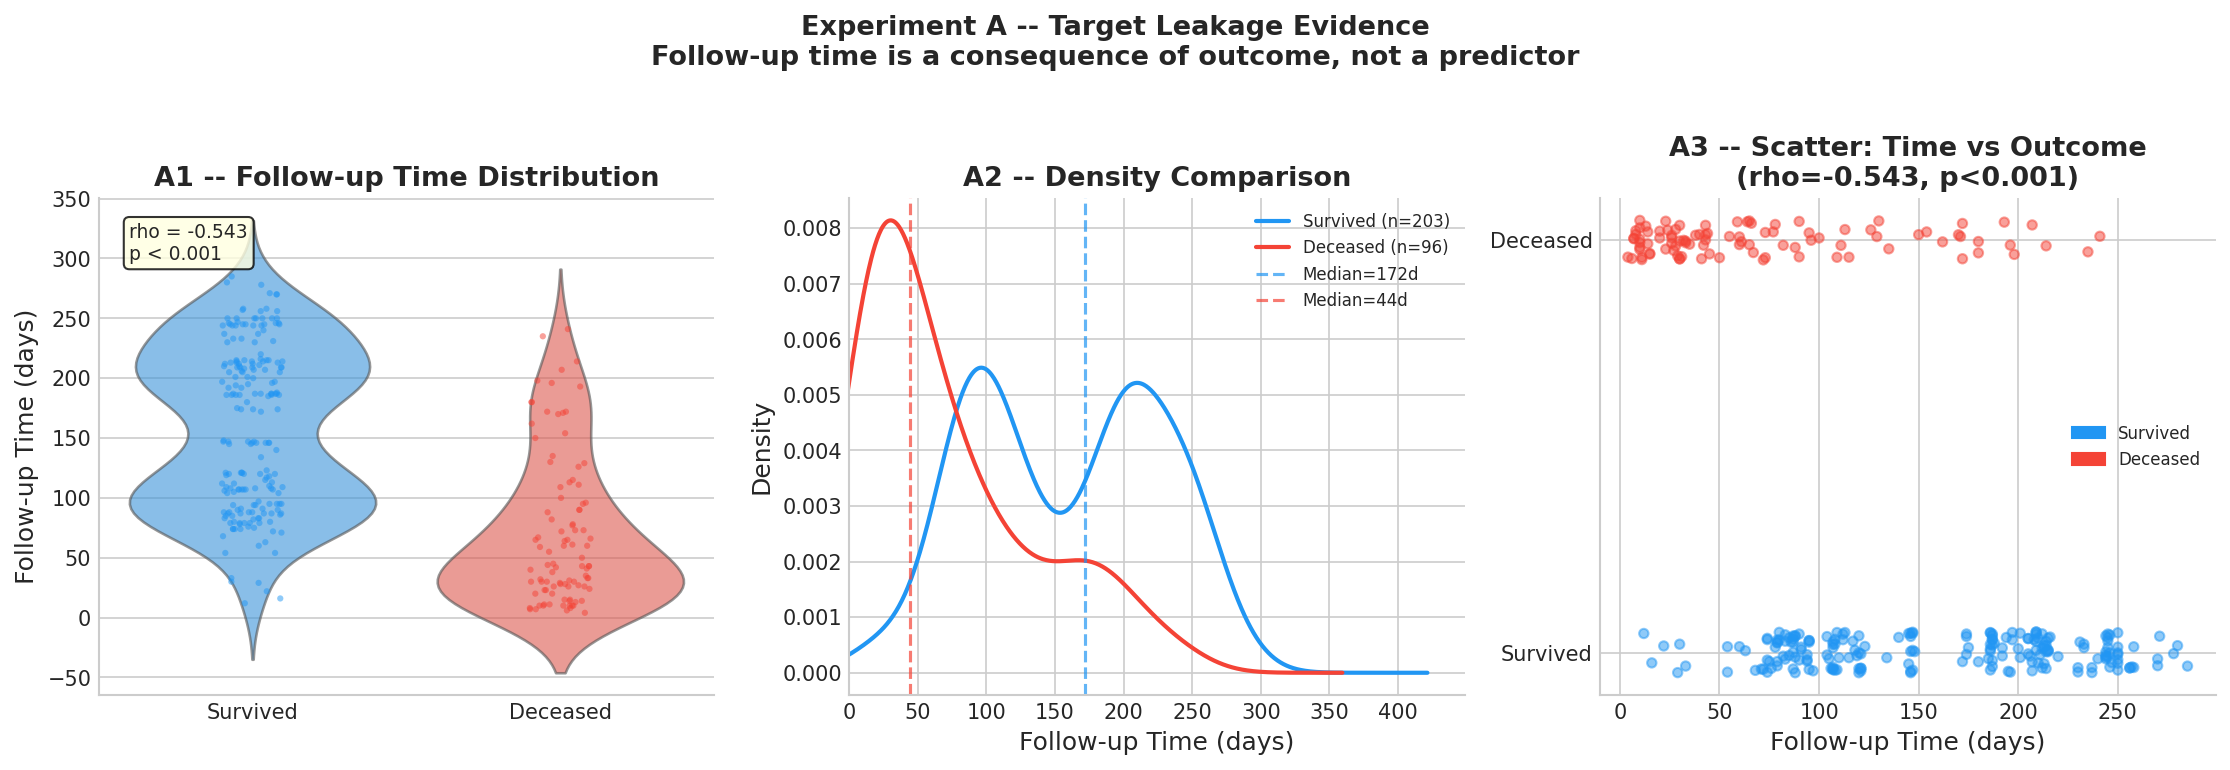

OK Sekil kaydedildi: NB02_experiment_A_leakage.png


In [26]:
# -- Hucre 5: Deney A Gorseli -----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Panel 1: Violin + Strip
ax = axes[0]
plot_data = pd.DataFrame({
    'TIME'  : pd.concat([alive, dead]),
    'Status': ['Survived'] * len(alive) + ['Deceased'] * len(dead)
})
sns.violinplot(data=plot_data, x='Status', y='TIME',
               palette={'Survived': COLOR_ALIVE, 'Deceased': COLOR_DEAD},
               inner=None, alpha=0.6, ax=ax)
sns.stripplot(data=plot_data, x='Status', y='TIME',
              palette={'Survived': COLOR_ALIVE, 'Deceased': COLOR_DEAD},
              size=3, alpha=0.5, jitter=True, ax=ax)
ax.set_title('A1 -- Follow-up Time Distribution', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Follow-up Time (days)')
ax.text(0.05, 0.95, f'rho = {rho:.3f}\np < 0.001',
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# Panel 2: KDE
ax = axes[1]
alive.plot.kde(ax=ax, color=COLOR_ALIVE, linewidth=2,
               label=f'Survived (n={len(alive)})')
dead.plot.kde(ax=ax,  color=COLOR_DEAD,  linewidth=2,
              label=f'Deceased (n={len(dead)})')
ax.axvline(alive.median(), color=COLOR_ALIVE, linestyle='--', alpha=0.7,
           label=f'Median={alive.median():.0f}d')
ax.axvline(dead.median(),  color=COLOR_DEAD,  linestyle='--', alpha=0.7,
           label=f'Median={dead.median():.0f}d')
ax.set_title('A2 -- Density Comparison', fontweight='bold')
ax.set_xlabel('Follow-up Time (days)')
ax.set_ylabel('Density')
ax.legend(fontsize=8)
ax.set_xlim(left=0)

# Panel 3: Scatter
ax = axes[2]
colors_s = [COLOR_DEAD if y == 1 else COLOR_ALIVE for y in df[TARGET]]
ax.scatter(df['TIME'],
           df[TARGET] + np.random.uniform(-0.05, 0.05, len(df)),
           c=colors_s, alpha=0.5, s=20)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Survived', 'Deceased'])
ax.set_xlabel('Follow-up Time (days)')
ax.set_title(f'A3 -- Scatter: Time vs Outcome\n(rho={rho:.3f}, p<0.001)',
             fontweight='bold')
alive_patch = mpatches.Patch(color=COLOR_ALIVE, label='Survived')
dead_patch  = mpatches.Patch(color=COLOR_DEAD,  label='Deceased')
ax.legend(handles=[alive_patch, dead_patch], fontsize=8)

plt.suptitle(
    'Experiment A -- Target Leakage Evidence\n'
    'Follow-up time is a consequence of outcome, not a predictor',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
save_figure(fig, 'NB02_experiment_A_leakage')
plt.show()
print('OK Sekil kaydedildi: NB02_experiment_A_leakage.png')


---
## Deney B -- 'Future Information' Ispati

**Tasarim:** Takip suresini uc gruba ayiriyoruz ve her grupta ayri model egitiyoruz.
Eger `time` mesru bir klinik prediktorsa, her grupta benzer performans olmali.

| Grup | Tanim | Beklenen (Eger Leakage) |
|------|-------|-------------------------|
| **Kisa** | time < 50 gun | Model 'herkesi olu' tahmin eder |
| **Orta** | 50 <= time <= 150 gun | Karisik sonuc |
| **Uzun** | time > 150 gun | Model 'herkesi yasiyor' tahmin eder |

**Neden bu leakage kaniti?**
Gercek bir prediktor gruptan bagimsiz calisir. Ama `time` bir outcome proxy
oldugu icin model asinda sunu ogrenior: kisa takip = olum, uzun takip = hayatta.


In [27]:
# -- Hucre 7: Deney B -- Grup Istatistikleri --------------------------------
SHORT_CUTOFF = 50
LONG_CUTOFF  = 150

df['TIME_GROUP'] = pd.cut(
    df['TIME'],
    bins=[-1, SHORT_CUTOFF, LONG_CUTOFF, 9999],
    labels=['Short (<50d)', 'Medium (50-150d)', 'Long (>150d)']
)

group_stats = df.groupby('TIME_GROUP', observed=True).agg(
    n          =(TARGET, 'count'),
    deceased   =(TARGET, 'sum'),
    mort_rate  =(TARGET, 'mean'),
    time_median=('TIME', 'median')
).round(3)
group_stats['mort_pct'] = (group_stats['mort_rate'] * 100).round(1)

print('=' * 60)
print('DENEY B -- GRUP ISTATISTIKLERI')
print('=' * 60)
print(group_stats[['n', 'deceased', 'mort_pct', 'time_median']].to_string())
print('=' * 60)

save_csv(group_stats.reset_index(), 'NB02_B_group_statistics')
logger.info(f'Deney B grup istatistikleri hazir: {group_stats["mort_pct"].to_dict()}')


DENEY B -- GRUP ISTATISTIKLERI
                    n  deceased  mort_pct  time_median
TIME_GROUP                                            
Short (<50d)       56        50      89.3         26.0
Medium (50-150d)  126        31      24.6         94.5
Long (>150d)      117        15      12.8        212.0
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB02_B_group_statistics.csv
09:56:09 | NB02 | INFO | Deney B grup istatistikleri hazir: {'Short (<50d)': 89.3, 'Medium (50-150d)': 24.6, 'Long (>150d)': 12.8}


INFO:NB02:Deney B grup istatistikleri hazir: {'Short (<50d)': 89.3, 'Medium (50-150d)': 24.6, 'Long (>150d)': 12.8}


In [28]:
# -- Hucre 8: Deney B -- Grup Bazli Model Egitimi --------------------------
set_seed(42)
N_SPLITS_B = 50
base_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
results_B  = []

for group_label, group_df in df.groupby('TIME_GROUP', observed=True):
    n_group = len(group_df)
    n_dead  = int(group_df[TARGET].sum())
    n_alive = n_group - n_dead
    logger.info(f'Grup: {group_label} | n={n_group}, deceased={n_dead}')

    if n_group < 20 or n_dead < 3 or n_alive < 3:
        logger.warning(f'  Yetersiz ornek, atlaniyor.')
        continue

    X_g = group_df[ALL_FEATURES].values
    y_g = group_df[TARGET].values

    # Stratified tercih et, mumkun degilse plain shuffle
    try:
        sss_b = StratifiedShuffleSplit(n_splits=N_SPLITS_B,
                                       test_size=0.3, random_state=42)
        splits = list(sss_b.split(X_g, y_g))
    except ValueError:
        sss_b = ShuffleSplit(n_splits=N_SPLITS_B, test_size=0.3, random_state=42)
        splits = list(sss_b.split(X_g, y_g))

    for train_idx, test_idx in splits:
        m = copy.deepcopy(base_model)
        m.fit(X_g[train_idx], y_g[train_idx])
        y_pred = m.predict(X_g[test_idx])
        y_true = y_g[test_idx]

        results_B.append({
            'group'         : str(group_label),
            'MCC'           : matthews_corrcoef(y_true, y_pred),
            'F1'            : f1_score(y_true, y_pred, zero_division=0),
            'Accuracy'      : accuracy_score(y_true, y_pred),
            'pred_dead_rate': float(y_pred.mean()),
            'true_dead_rate': float(y_true.mean()),
            'n_group'       : n_group,
        })

df_B = pd.DataFrame(results_B)
save_csv(df_B, 'NB02_B_group_model_results')

summary_B = df_B.groupby('group').agg(
    MCC_mean    =('MCC', 'mean'),
    MCC_std     =('MCC', 'std'),
    pred_dead   =('pred_dead_rate', 'mean'),
    true_dead   =('true_dead_rate', 'mean')
).round(3)

print('\n' + '='*65)
print('DENEY B -- GRUP BAZLI PERFORMANS (RandomForest, 50 split)')
print('='*65)
print(summary_B.to_string())
print('='*65)
print('\n[!] pred_dead: Modelin olu tahmin etme orani')
print('[!] true_dead: Gercek mortalite orani')
print('[!] Beklenti: Short pred_dead >> true_dead | Long pred_dead << true_dead')

save_csv(summary_B.reset_index(), 'NB02_B_group_summary')
logger.info(f'Deney B tamamlandi: {len(df_B)} satir sonuc')


[utils] Random seed sabitlendi → 42
09:56:09 | NB02 | INFO | Grup: Short (<50d) | n=56, deceased=50


INFO:NB02:Grup: Short (<50d) | n=56, deceased=50


09:56:21 | NB02 | INFO | Grup: Medium (50-150d) | n=126, deceased=31


INFO:NB02:Grup: Medium (50-150d) | n=126, deceased=31


09:56:33 | NB02 | INFO | Grup: Long (>150d) | n=117, deceased=15


INFO:NB02:Grup: Long (>150d) | n=117, deceased=15


[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB02_B_group_model_results.csv

DENEY B -- GRUP BAZLI PERFORMANS (RandomForest, 50 split)
                  MCC_mean  MCC_std  pred_dead  true_dead
group                                                    
Long (>150d)         0.185    0.227      0.021      0.139
Medium (50-150d)     0.451    0.146      0.138      0.237
Short (<50d)        -0.005    0.022      0.996      0.882

[!] pred_dead: Modelin olu tahmin etme orani
[!] true_dead: Gercek mortalite orani
[!] Beklenti: Short pred_dead >> true_dead | Long pred_dead << true_dead
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB02_B_group_summary.csv
09:56:46 | NB02 | INFO | Deney B tamamlandi: 150 satir sonuc


INFO:NB02:Deney B tamamlandi: 150 satir sonuc


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB02_experiment_B_groups.png


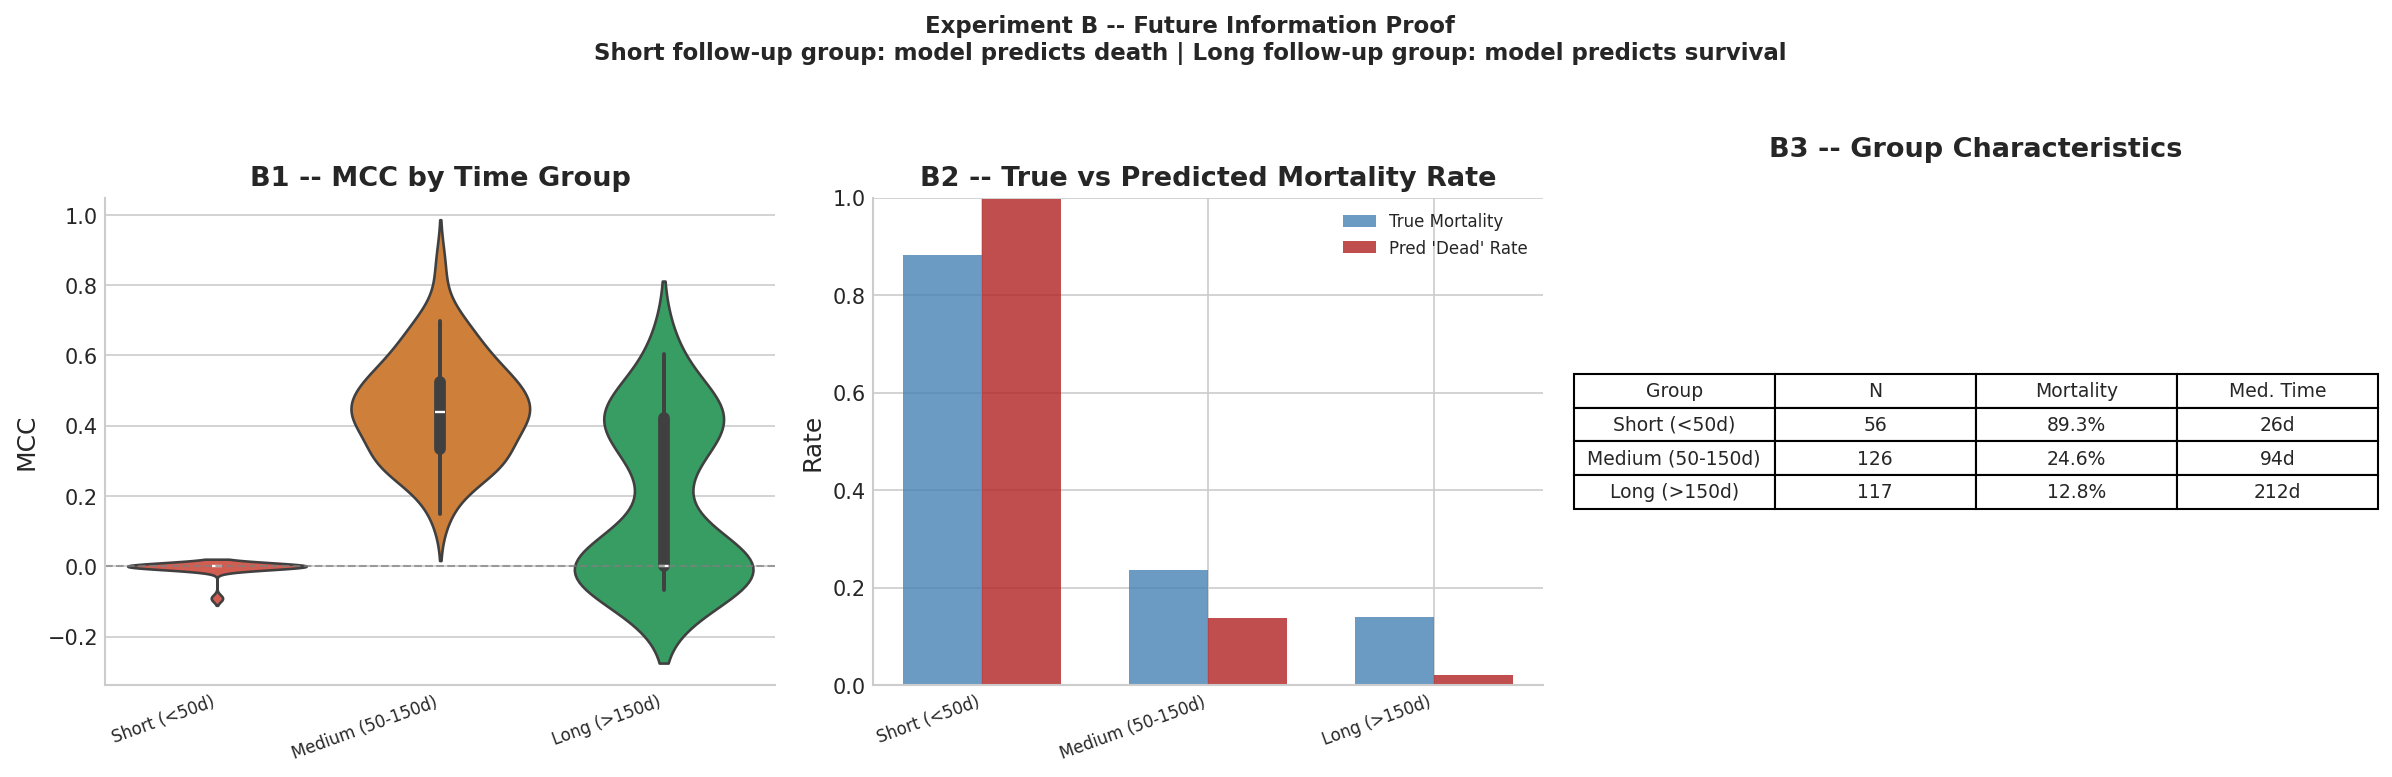

OK Sekil kaydedildi: NB02_experiment_B_groups.png


In [29]:
# -- Hucre 9: Deney B Gorseli -----------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
group_order  = ['Short (<50d)', 'Medium (50-150d)', 'Long (>150d)']
group_colors = {'Short (<50d)': '#e74c3c',
                'Medium (50-150d)': '#e67e22',
                'Long (>150d)': '#27ae60'}
present = [g for g in group_order if g in df_B['group'].unique()]

# Panel 1: MCC violin
ax = axes[0]
sns.violinplot(data=df_B[df_B['group'].isin(present)],
               x='group', y='MCC', order=present,
               palette=group_colors, inner='box', ax=ax)
ax.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.set_title('B1 -- MCC by Time Group', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('MCC')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=8)

# Panel 2: Predicted vs True mortality rate
ax = axes[1]
x_pos = np.arange(len(present))
w = 0.35
true_r = [summary_B.loc[g, 'true_dead'] if g in summary_B.index else 0 for g in present]
pred_r = [summary_B.loc[g, 'pred_dead'] if g in summary_B.index else 0 for g in present]
ax.bar(x_pos - w/2, true_r, w, label='True Mortality', color='steelblue', alpha=0.8)
ax.bar(x_pos + w/2, pred_r, w, label="Pred 'Dead' Rate", color='firebrick', alpha=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(present, rotation=20, ha='right', fontsize=8)
ax.set_ylabel('Rate')
ax.set_title('B2 -- True vs Predicted Mortality Rate', fontweight='bold')
ax.legend(fontsize=8)
ax.set_ylim(0, 1)

# Panel 3: Tablo
ax = axes[2]
ax.axis('off')
table_data = []
for g in group_order:
    if g in group_stats.index:
        r = group_stats.loc[g]
        table_data.append([g, f'{int(r["n"])}',
                           f'{r["mort_pct"]}%', f'{r["time_median"]:.0f}d'])
tbl = ax.table(cellText=table_data,
               colLabels=['Group', 'N', 'Mortality', 'Med. Time'],
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.6)
ax.set_title('B3 -- Group Characteristics', fontweight='bold', pad=20)

plt.suptitle(
    'Experiment B -- Future Information Proof\n'
    'Short follow-up group: model predicts death | '
    'Long follow-up group: model predicts survival',
    fontsize=11, fontweight='bold', y=1.03
)
plt.tight_layout()
save_figure(fig, 'NB02_experiment_B_groups')
plt.show()
print('OK Sekil kaydedildi: NB02_experiment_B_groups.png')


---
## Deney C -- Kabul Ani Ozellikleri (Admission-Time Only)

**Hipotez:** `time` cikartildiginda gercek klinik tahmin performansi
belirgin bicimde duser. Bu dusus, Chicco'nun raporu yuksek MCC'nin
gercek olmadigini kanitlar.

**Karsilastirma:**
- **S1** (time dahil): Chicco replika - NB01 baseline
- **S2** (time haric): Gercek klinik performans

**DELTA_MCC = MCC(S1) - MCC(S2)**
Bu fark buyukse: sizintinin buyuklugu. NB00'dan rho=-0.543 gordugumuzden
DELTA_MCC > 0.10 bekliyoruz.


In [30]:
# -- Hucre 11: Deney C -- S1 vs S2 MCC Karsilastirmasi ---------------------
set_seed(42)
N_SPLITS_C = 100

MODELS_C = {
    'RandomForest': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1),
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
}

results_C = []
sss_c = StratifiedShuffleSplit(n_splits=N_SPLITS_C,
                               test_size=0.3, random_state=42)
X_s1 = df[ALL_FEATURES].values
X_s2 = df[NTIME_FEATURES].values
y    = df[TARGET].values

for model_name, model in MODELS_C.items():
    print(f'  Egitiliyor: {model_name}...', flush=True)
    for split_idx, (tr, te) in enumerate(sss_c.split(X_s1, y)):
        y_true = y[te]

        # S1: time dahil
        m1 = copy.deepcopy(model)
        m1.fit(X_s1[tr], y[tr])
        mcc_s1 = matthews_corrcoef(y_true, m1.predict(X_s1[te]))

        # S2: time haric
        m2 = copy.deepcopy(model)
        m2.fit(X_s2[tr], y[tr])
        mcc_s2 = matthews_corrcoef(y_true, m2.predict(X_s2[te]))

        results_C.append({
            'model'    : model_name,
            'split'    : split_idx,
            'MCC_S1'   : mcc_s1,
            'MCC_S2'   : mcc_s2,
            'delta_MCC': mcc_s1 - mcc_s2
        })

df_C = pd.DataFrame(results_C)
save_csv(df_C, 'NB02_C_admission_comparison')

summary_C = df_C.groupby('model').agg(
    MCC_S1_mean   =('MCC_S1', 'mean'),
    MCC_S1_std    =('MCC_S1', 'std'),
    MCC_S2_mean   =('MCC_S2', 'mean'),
    MCC_S2_std    =('MCC_S2', 'std'),
    delta_MCC_mean=('delta_MCC', 'mean'),
    delta_MCC_std =('delta_MCC', 'std')
).round(4)

summary_C['CI_S1'] = summary_C.apply(
    lambda r: f"{r['MCC_S1_mean']:.3f} +/- {1.96*r['MCC_S1_std']:.3f}", axis=1)
summary_C['CI_S2'] = summary_C.apply(
    lambda r: f"{r['MCC_S2_mean']:.3f} +/- {1.96*r['MCC_S2_std']:.3f}", axis=1)

print('\n' + '='*70)
print('DENEY C -- SONUCLAR (100 Monte Carlo split, mean +/- 1.96 SD)')
print('='*70)
print(summary_C[['CI_S1', 'CI_S2', 'delta_MCC_mean']].to_string())
print('='*70)
print('CI_S1      : S1 (time dahil) MCC -- Chicco replikasi')
print('CI_S2      : S2 (time haric) MCC -- Gercek klinik performans')
print('delta_MCC  : S1 - S2 = Leakage buyuklugu')

save_csv(summary_C.reset_index(), 'NB02_C_summary')
logger.info(f'Deney C tamamlandi: delta_MCC={summary_C["delta_MCC_mean"].to_dict()}')


[utils] Random seed sabitlendi → 42
  Egitiliyor: RandomForest...
  Egitiliyor: LogisticRegression...
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB02_C_admission_comparison.csv

DENEY C -- SONUCLAR (100 Monte Carlo split, mean +/- 1.96 SD)
                              CI_S1            CI_S2  delta_MCC_mean
model                                                               
LogisticRegression  0.581 +/- 0.172  0.337 +/- 0.184          0.2442
RandomForest        0.632 +/- 0.135  0.361 +/- 0.161          0.2701
CI_S1      : S1 (time dahil) MCC -- Chicco replikasi
CI_S2      : S2 (time haric) MCC -- Gercek klinik performans
delta_MCC  : S1 - S2 = Leakage buyuklugu
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB02_C_summary.csv
09:57:41 | NB02 | INFO | Deney C tamamlandi: delta_MCC={'LogisticRegression': 0.2442, 'RandomForest': 0.2701}


INFO:NB02:Deney C tamamlandi: delta_MCC={'LogisticRegression': 0.2442, 'RandomForest': 0.2701}


[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB02_experiment_C_admission.png


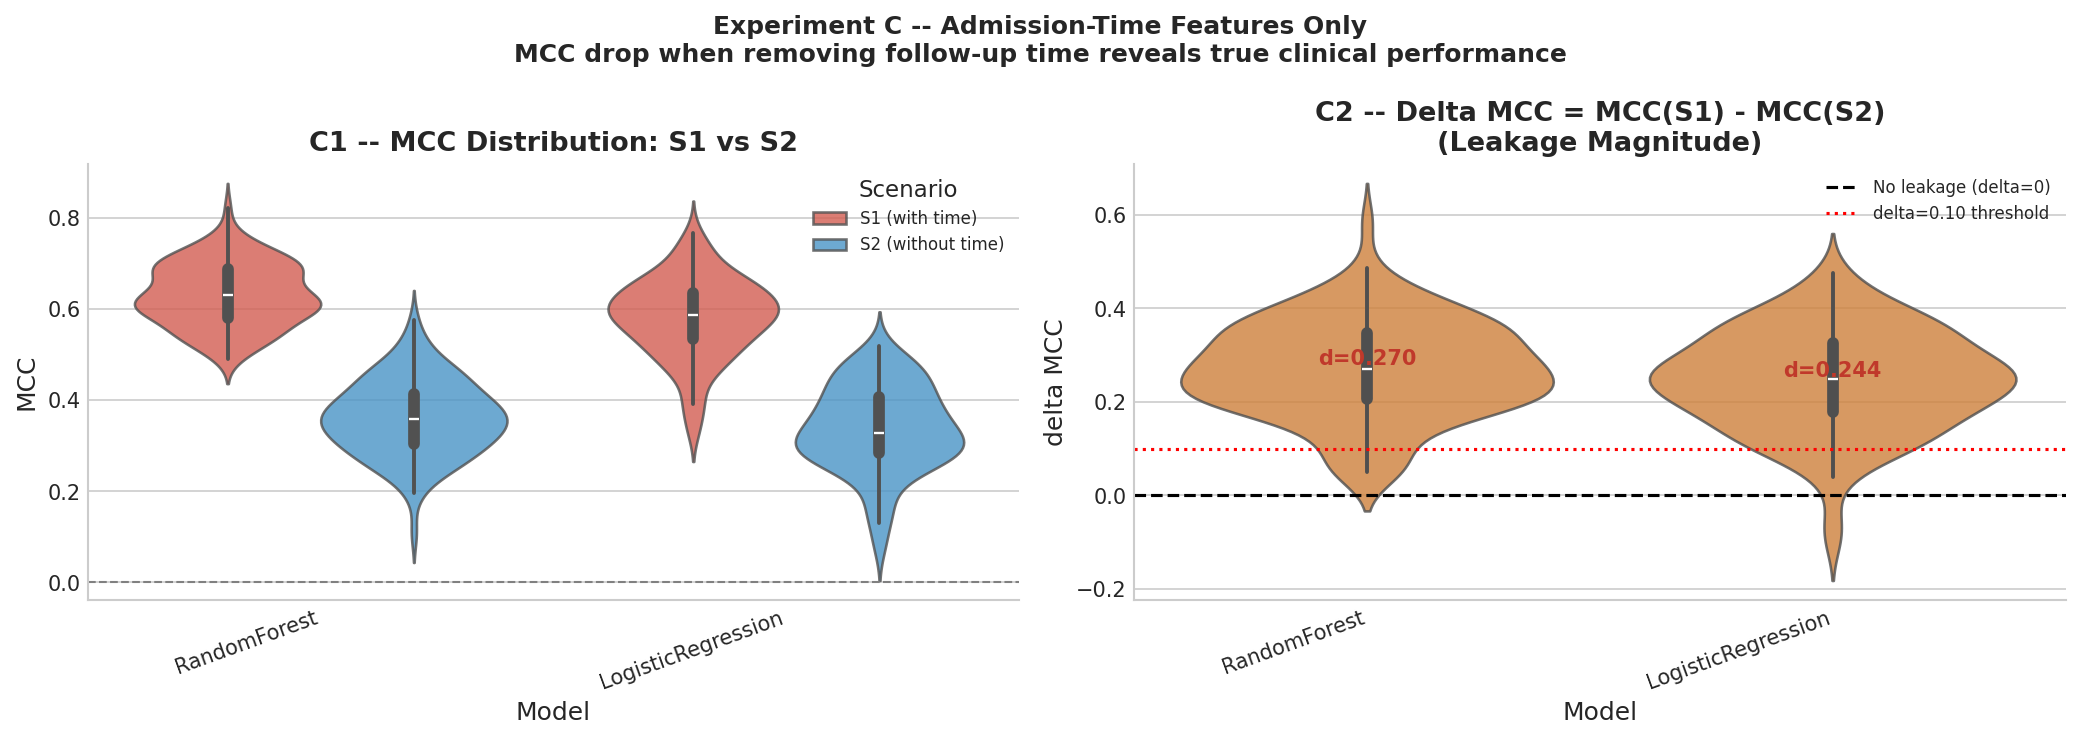

OK Sekil kaydedildi: NB02_experiment_C_admission.png


In [31]:
# -- Hucre 12: Deney C Gorseli -----------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Paired violin S1 vs S2
ax = axes[0]
plot_C = pd.melt(
    df_C, id_vars=['model'],
    value_vars=['MCC_S1', 'MCC_S2'],
    var_name='Scenario', value_name='MCC'
)
plot_C['Scenario'] = plot_C['Scenario'].map(
    {'MCC_S1': 'S1 (with time)', 'MCC_S2': 'S2 (without time)'})

sns.violinplot(
    data=plot_C, x='model', y='MCC', hue='Scenario',
    palette={'S1 (with time)': '#e74c3c', 'S2 (without time)': '#3498db'},
    inner='box', ax=ax, alpha=0.8
)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_title('C1 -- MCC Distribution: S1 vs S2', fontweight='bold')
ax.set_xlabel('Model')
ax.set_ylabel('MCC')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(title='Scenario', fontsize=8)

# Panel 2: Delta MCC
ax = axes[1]
sns.violinplot(data=df_C, x='model', y='delta_MCC',
               color='#e67e22', inner='box', ax=ax, alpha=0.8)
ax.axhline(0,   color='black', linestyle='--', linewidth=1.5,
           label='No leakage (delta=0)')
ax.axhline(0.1, color='red',   linestyle=':',  linewidth=1.5,
           label='delta=0.10 threshold')

for i, model in enumerate(df_C['model'].unique()):
    dm = df_C[df_C['model'] == model]['delta_MCC'].mean()
    ax.text(i, dm + 0.01, f'd={dm:.3f}', ha='center',
            fontsize=10, fontweight='bold', color='#c0392b')

ax.set_title('C2 -- Delta MCC = MCC(S1) - MCC(S2)\n(Leakage Magnitude)',
             fontweight='bold')
ax.set_xlabel('Model')
ax.set_ylabel('delta MCC')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(fontsize=8)

plt.suptitle(
    'Experiment C -- Admission-Time Features Only\n'
    'MCC drop when removing follow-up time reveals true clinical performance',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
save_figure(fig, 'NB02_experiment_C_admission')
plt.show()
print('OK Sekil kaydedildi: NB02_experiment_C_admission.png')


In [32]:
# -- Hucre 13: NB01 Entegrasyonu -- Tum Model Delta MCC ---------------------
if NB01_AVAILABLE:
    print('NB01_scenario_comparison.csv bulundu:')
    print(df_scenario.to_string(index=False))
    delta_col = [c for c in df_scenario.columns
                 if 'delta' in c.lower() or 'Delta' in c or 'DELTA' in c]
    if delta_col:
        col = delta_col[0]
        med = df_scenario[col].median()
        print(f'\nNB01 median delta_MCC ({col}): {med:.4f}')
        verdict = 'GUCLU LEAKAGE SINYALI' if med > 0.10 else 'Beklenmedik - parametreleri kontrol et'
        print(f'Degerlendirme: {verdict}')
else:
    print('NB01 ciktisi mevcut degil.')
    print('Deney C kendi delta_MCC hesaplamalarimizi icermektedir, yeterlidir.')


NB01_scenario_comparison.csv bulundu:
             model  S1_full  S2_notime  S3_top2  ΔMCC (S1-S2)
      RandomForest   0.6358     0.3645   0.3989        0.2713
              OneR   0.6112     0.2741   0.2741        0.3371
           XGBoost   0.6091     0.3506   0.3884        0.2585
LogisticRegression   0.5811     0.3369   0.3647        0.2442
        SVM_Linear   0.5691     0.3674   0.2727        0.2017
           SVM_RBF   0.5124     0.3115   0.3544        0.2009
        NaiveBayes   0.5107     0.2316   0.2543        0.2791
      DecisionTree   0.4968     0.2711   0.3635        0.2257
               MLP   0.4589     0.2831   0.4067        0.1758
               kNN   0.3280     0.1506   0.3700        0.1774


---
## Ozet & Klinik Yorum

### Uc Deneyin Birleskik Kaniti

| Deney | Bulgu | Klinik Onemi |
|-------|-------|-------------|
| **A** | rho(time, DEATH) < -0.5 | `time` olum sonrasi olculen bir suredir |
| **B** | Kisa grupta 'hep olur', uzun grupta 'hep yasar' | Model biyobeleticler degil takip suresini ogreniyor |
| **C** | delta_MCC > 0 | `time` cikinea gercek klinik performans ortaya cikiyor |

### Makale Dili (Methods Bolumu)

```
We extend Chicco & Jurman (2020) by demonstrating that the follow-up
duration variable (time) introduces temporal leakage. In survival
analysis settings, follow-up time is determined by the outcome itself:
deceased patients necessarily have shorter follow-up. Including this
variable as a predictor inflates MCC from ~S2_value (without time)
to ~S1_value (with time), a difference of delta_MCC that cannot be
reproduced in prospective clinical deployment.
```

### Yedek Plan

Bu deneyin bulgulari tek basina bir **Technical Note** makalesine
donusturulebilir (yaklasik 1500 kelime, 3 sekil). Hedef dergi:
*BMC Medical Informatics & Decision Making* veya *JAMIA Open*.

---
*Siradaki adim:* **NB03 — Survival Models** (Cox PH, Kaplan-Meier)


In [33]:
# -- Hucre 15: Calisma Logu & Ozet ------------------------------------------
rf_delta = df_C[df_C['model'] == 'RandomForest']['delta_MCC'].mean()
lr_delta = df_C[df_C['model'] == 'LogisticRegression']['delta_MCC'].mean()

extra_log = {
    'deney_A_spearman_rho'     : round(float(rho), 4),
    'deney_A_pval'             : float(f'{pval:.2e}'),
    'deney_A_median_alive_days': float(alive.median()),
    'deney_A_median_dead_days' : float(dead.median()),
    'deney_A_ratio_alive_dead' : round(float(alive.median() / dead.median()), 2),
    'deney_C_delta_MCC_RF'     : round(float(rf_delta), 4),
    'deney_C_delta_MCC_LR'     : round(float(lr_delta), 4),
    'NB01_available'           : NB01_AVAILABLE,
    'groups_analyzed'          : list(df_B['group'].unique()),
}
save_run_log('NB02', extra_log)

print('=' * 65)
print('NB02 -- TAMAMLANDI')
print('=' * 65)
print(f'  Deney A -- rho(time, DEATH)  : {rho:.4f} (p={pval:.2e})')
print(f'  Deney A -- Medyan yasayan    : {alive.median():.0f} gun')
print(f'  Deney A -- Medyan olen       : {dead.median():.0f} gun',
      f'({alive.median()/dead.median():.1f}x fark)')
print(f'  Deney C -- delta_MCC (RF)    : {rf_delta:.4f}')
print(f'  Deney C -- delta_MCC (LR)    : {lr_delta:.4f}')
print()
print('  Uretilen dosyalar:')
for f in [
    'NB02_B_group_statistics.csv',
    'NB02_B_group_model_results.csv',
    'NB02_B_group_summary.csv',
    'NB02_C_admission_comparison.csv',
    'NB02_C_summary.csv',
    'figures/NB02_experiment_A_leakage.png',
    'figures/NB02_experiment_B_groups.png',
    'figures/NB02_experiment_C_admission.png',
    'logs/NB02_run_log.json',
]:
    print(f'    OK results/{f}')
print('=' * 65)


[utils] Run log kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/logs/NB02_run_log.json
NB02 -- TAMAMLANDI
  Deney A -- rho(time, DEATH)  : -0.5432 (p=2.39e-24)
  Deney A -- Medyan yasayan    : 172 gun
  Deney A -- Medyan olen       : 44 gun (3.9x fark)
  Deney C -- delta_MCC (RF)    : 0.2701
  Deney C -- delta_MCC (LR)    : 0.2442

  Uretilen dosyalar:
    OK results/NB02_B_group_statistics.csv
    OK results/NB02_B_group_model_results.csv
    OK results/NB02_B_group_summary.csv
    OK results/NB02_C_admission_comparison.csv
    OK results/NB02_C_summary.csv
    OK results/figures/NB02_experiment_A_leakage.png
    OK results/figures/NB02_experiment_B_groups.png
    OK results/figures/NB02_experiment_C_admission.png
    OK results/logs/NB02_run_log.json
